<a href="https://colab.research.google.com/github/Darioldeveloper-dev/CSC4110-G01/blob/main/G01_U4_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning
## Group G01: Student Performance Factors
### Task 4: Classification
- **Registration number:** COM/0043/23
- **owner:** Emmanuel Rotich (Member 5)
- **Module:** 5

**Contents**
1. Setup and target
2. Stratified split and class balance
3. Logistic regression
4. Other classifiers
5. Comparison and ROC curve
6. Written answer

In [24]:
# Mount Drive, import libraries and load the cleaned data from Task 2.2
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score)

df_clean = pd.read_csv("/content/drive/MyDrive/CSC4110_G01/data/clean_students.csv")
out = "/content/drive/MyDrive/CSC4110_G01/outputs/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
# The classification target was created in Task 2.2: 1 if Exam_Score >= 70, else 0
y = df_clean['high_score']

# Class counts and percentages
counts = y.value_counts().sort_index()
print(pd.DataFrame({'count': counts, 'percent': (counts / len(y) * 100).round(1)}))

# Features: drop Exam_Score (it defines the target) and high_score itself
X = df_clean.drop(columns=['Exam_Score', 'high_score'])

# Stratified 80/20 split keeps the same class shares in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Class 1 share, train:", round(y_train.mean() * 100, 2), "% test:", round(y_test.mean() * 100, 2), "%")
print(X_train.shape, X_test.shape)

# Scale using the training set only (needed by KNN, SVM and logistic regression)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

            count  percent
high_score                
0            4982     75.4
1            1625     24.6
Class 1 share, train: 24.6 % test: 24.58 %
(5285, 22) (1322, 22)


In [26]:
# 'balanced' makes mistakes on the rarer class cost more during training
for weight in [None, 'balanced']:
    model = LogisticRegression(class_weight=weight, max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train)
    pred_w = model.predict(X_test_scaled)
    print(f"class_weight = {weight}: recall for class 1 = {recall_score(y_test, pred_w):.4f}, "
          f"precision = {precision_score(y_test, pred_w):.4f}")

class_weight = None: recall for class 1 = 0.9323, precision = 0.9650
class_weight = balanced: recall for class 1 = 0.9785, precision = 0.8480


### Class Balancing Trade-Off Summary

While class balancing lowers overall accuracy from `0.9750` to `0.9516` by generating more false positives, it is the better choice here because our goal prioritizes high **recall**—making it far more important to catch every deserving high-scoring student than to avoid conducting a few extra interviews.

[[986  11]
 [ 22 303]]


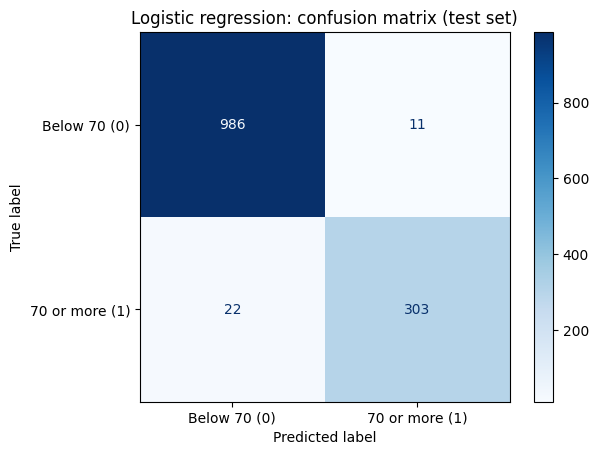

                precision    recall  f1-score   support

  Below 70 (0)     0.9782    0.9890    0.9835       997
70 or more (1)     0.9650    0.9323    0.9484       325

      accuracy                         0.9750      1322
     macro avg     0.9716    0.9606    0.9659      1322
  weighted avg     0.9749    0.9750    0.9749      1322



In [27]:
# Fit the logistic regression and predict classes and probabilities
log_reg = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_scaled, y_train)
pred = log_reg.predict(X_test_scaled)
proba = log_reg.predict_proba(X_test_scaled)[:, 1]    # probability of class 1

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_test, pred)
print(cm)
disp = ConfusionMatrixDisplay(cm, display_labels=['Below 70 (0)', '70 or more (1)'])
disp.plot(cmap='Blues')
plt.title('Logistic regression: confusion matrix (test set)')
plt.savefig(out + 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(classification_report(y_test, pred, target_names=['Below 70 (0)', '70 or more (1)'], digits=4))

### Confusion Matrix and Classification Metrics Interpretation

**Confusion matrix breakdown (1,322 test students):**

* True Negatives (`986`): below-70 students correctly identified as not qualifying.
* False Positives (`11`): below-70 students wrongly flagged as high scorers.
* False Negatives (`22`): actual high scorers missed by the model.
* True Positives (`303`): high scorers correctly identified.

**Key classification metrics:**

* Precision (`0.965`): 303 ÷ (303 + 11) = 0.965, so 96.5% of the students flagged by the model genuinely achieved a high score.
* Recall (`0.932`): 303 ÷ (303 + 22) = 0.932, so the model caught 93.2% of all actual high-scoring students in the test set.
* F1-score (`0.9484`): the harmonic mean of precision and recall. It penalises extreme imbalances, so it stays high only when both are strong together.

In [28]:
# Fit every classifier on the scaled training data
models = {'Logistic regression': log_reg}
for k in [3, 5, 7]:
    models[f'KNN (k={k})'] = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
models['Gaussian Naive Bayes'] = GaussianNB().fit(X_train_scaled, y_train)
models['SVM (RBF)'] = SVC(probability=True, random_state=42).fit(X_train_scaled, y_train)

# One row per model: test accuracy, precision, recall and F1 for class 1
results_clf = pd.DataFrame({
    name: {'Accuracy': accuracy_score(y_test, m.predict(X_test_scaled)),
           'Precision': precision_score(y_test, m.predict(X_test_scaled)),
           'Recall': recall_score(y_test, m.predict(X_test_scaled)),
           'F1': f1_score(y_test, m.predict(X_test_scaled))}
    for name, m in models.items()}).T
print(results_clf.round(4))

                      Accuracy  Precision  Recall      F1
Logistic regression     0.9750     0.9650  0.9323  0.9484
KNN (k=3)               0.8737     0.7992  0.6492  0.7165
KNN (k=5)               0.8903     0.8750  0.6462  0.7434
KNN (k=7)               0.8865     0.8889  0.6154  0.7273
Gaussian Naive Bayes    0.8964     0.8176  0.7446  0.7794
SVM (RBF)               0.9644     0.9664  0.8862  0.9246


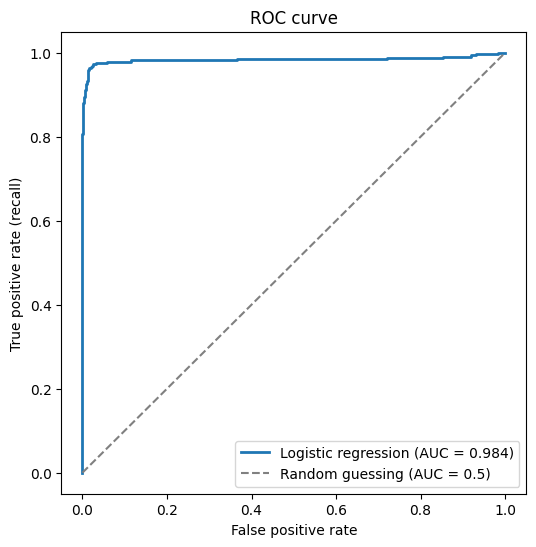

AUC: 0.9836


In [29]:
# ROC: true positive rate against false positive rate as the probability threshold moves
auc = roc_auc_score(y_test, proba)
fpr, tpr, thresholds = roc_curve(y_test, proba)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'Logistic regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guessing (AUC = 0.5)')
plt.title('ROC curve')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate (recall)')
plt.legend(loc='lower right')
plt.savefig(out + 'roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("AUC:", round(auc, 4))

In [30]:
assert len(y_train) == 5285 and len(y_test) == 1322
assert abs(y_train.mean() - y_test.mean()) < 0.005          # same class shares
assert 'Exam_Score' not in X_train.columns and 'high_score' not in X_train.columns
assert cm.sum() == len(y_test) and len(results_clf) == 6
print("Task 4 checks passed")

Task 4 checks passed


### Classification Splitting, Metric Priority, and KNN Sensitivity

**1. Why `stratify=y` matters**

* The target (`high_score`) is imbalanced (75.4% below 70 against 24.6% at or above 70), so `stratify=y` forces the training and test sets to keep that same class ratio (24.60% and 24.58%).
* Without it, a random split can drift. With the same `random_state=42` and no stratification, the test set had 26.32% high scorers (348 students) and the training set 24.16%, against 24.6% overall. Across seeds 0 to 5 the test share ranged from 23.75% to 27.69%. The drift is modest here, but it would skew recall, precision and F1 comparisons, and it matters more with smaller datasets or rarer classes.

**2. Why a school cares more about recall than precision here**

* In a recognition or scholarship screening context, a false negative means overlooking a genuinely deserving student, whereas a false positive costs only one extra review or interview.
* Prioritising recall catches as many true high performers as possible, accepting a few extra interviews as a worthwhile trade-off.

**3. Why `k = 3` behaves differently from `k = 7` in KNN**

* A small neighbourhood (`k = 3`) gives a jagged, locally sensitive boundary that reacts to individual noisy points. A larger one (`k = 7`) averages over more neighbours and smooths the noise.
* The results show this pattern. As k grows from 3 to 7, precision rises (0.80 to 0.89) while recall falls (0.65 to 0.62). Small k flags more students, some wrongly, and larger k becomes more cautious.
* Accuracy stayed within 0.87 to 0.89 for all three, so changing k could not fix the overall weakness. The likely cause is distance dilution across 22 features (not formally tested).

### Model Comparison: Logistic Regression vs. k-Nearest Neighbors (KNN)

**Linear boundary (logistic regression)**

* Logistic regression learns one weighted combination of all the features and draws a smooth, linear decision boundary. The relationship between student factors and exam performance is largely linear (Module 4's linear regression reached R² = 0.77, which leaves about a quarter of the variation unexplained), so this structure fits the data well. It achieved `0.9750` test accuracy (`0.9818` train, so no meaningful overfitting) and an F1-score of `0.9484`.
* Its largest weights are `Attendance` (`3.7`), `effort` (`2.7`), `Access_to_Resources` (`~1.55`) and `Previous_Scores` (`~1.55`). They tell the same story as the regression analysis.

**Distance voting (KNN)**

* KNN builds no explicit model. It classifies each student by majority vote among the k closest students in feature space. It scored only `0.87` to `0.89` accuracy, with a much weaker recall of `0.62` to `0.65`.
* Likely cause (hypothesis, not tested): across 22 scaled features, many of them binary 0/1 indicators or weak predictors, Euclidean distances get diluted by uninformative dimensions, which drowns out the strong signal concentrated in a few key predictors.
* Practical drawbacks: KNN needs feature scaling and must compute distances to the whole training set at prediction time, whereas logistic regression predicts almost instantly with a dot product.

### Model Comparison: Naive Bayes vs. Support Vector Machine (SVM)

**Probabilistic classification (Gaussian Naive Bayes)**

* For a new student, Naive Bayes multiplies how likely each feature value is under class 1 against class 0, and assigns the class with the higher result.
* Likely reasons for its lower accuracy (`0.8964`): it assumes features are independent given the class, and that is violated here because `effort` is built from `Hours_Studied` and `Attendance`, so correlated evidence is counted twice. It also assumes Gaussian-shaped features, which the 0/1 columns violate. These are likely causes, not tested ones.

**Geometric margin maximisation (SVM with RBF kernel)**

* The SVM searches for the boundary that separates the two classes with the widest possible margin between the closest points (the support vectors). The RBF kernel lets that boundary curve around complex regions. A new student is classified by which side of the boundary they land on.
* It fit the training set more tightly than logistic regression (`0.9888` train against `0.9644` test, a gap of about 2.4 points).

### Final Classification Recommendation and Accuracy Assessment

**Recommended model: logistic regression**

* Logistic regression has the highest test accuracy (`0.9750`), F1-score (`0.9484`) and recall (`0.9323`). It ties the SVM on AUC (`0.9836` for both) and is essentially level on precision (`0.9650` against the SVM's `0.9664`). It is also fast, lightweight and explainable through its feature weights. Because the SVM ties it on AUC, simplicity and explainability decide the choice.
* The SVM ranks second (`0.9644` accuracy). It fits the training data more tightly, runs slower, is harder to interpret, and misses more deserving high scorers (recall `0.8862` against `0.9323`).

**Why accuracy alone misleads**

* 75.4% of students score below 70, so a trivial model that predicts "below 70" for everyone would still reach 75.4% accuracy while catching zero high scorers.
* Our 97.5% accuracy is meaningful only because it is backed by high precision (`0.965`) and high recall (`0.932`), which shows the model really identifies the minority high-scoring group rather than exploiting the class imbalance.